# Hinchamiento del extrudado con un fundido viscoelástico

Al salir de un dado, un fundido polimérico **se hincha**: el extrudado queda más grueso que la abertura del dado. Hay dos causas:

1. **Reorganización del perfil de velocidad** (también en un fluido newtoniano). Dentro del dado el perfil es parabólico, con la velocidad máxima en el centro y cero en la pared. Fuera del dado no hay pared y el perfil se vuelve plano (flujo tapón). Para conservar el caudal con una velocidad uniforme, la sección se ensancha. En flujo plano reptante el hinchamiento newtoniano es $B = h_\infty / H \approx 1.19$.
2. **Elasticidad** (memoria del fluido). En el dado las cadenas se orientan y estiran en la dirección del flujo, con una primera diferencia de esfuerzos normales $N_1 = \tau_{xx} - \tau_{yy} > 0$. Fuera del dado esos esfuerzos se relajan, el extrudado se acorta en la dirección del flujo y se ensancha en la transversal.

Este cuaderno usa el módulo `Source/Physics/FreeSurface.py` para calcular la **superficie libre estacionaria** del extrudado, primero con un fluido newtoniano y luego con un fluido **Giesekus**, con continuación en el número de Weissenberg $\mathrm{Wi} = \lambda U / H$.

## El método: línea de corriente (Tanner)

La superficie libre tiene dos condiciones:

- **Dinámica**: no hay tracción, $\boldsymbol{\sigma}\cdot\mathbf{n} = 0$. En el método de elementos finitos es la condición *natural*: basta con no poner ninguna condición en esa frontera.
- **Cinemática**: el fluido no la cruza, $\mathbf{u}\cdot\mathbf{n} = 0$. La superficie es la línea de corriente que sale del borde del dado.

`FreeSurface.solve()` itera hasta que la superficie deja de moverse. En cada iteración:

1. Resuelve el flujo en el dominio actual (cualquier física del código: newtoniano, Cross–WLF, viscoelástico, no isotermo).
2. Integra $\dfrac{dh}{dx} = \dfrac{v}{u}$ a lo largo de la superficie desde el borde del dado, con $h(0) = H$.
3. Mueve los nodos aguas abajo del borde en la dirección transversal, $y \to y\,h_\text{nueva}(x)/h_\text{vieja}(x)$, con `Model.moveNodes`, que reconstruye la geometría.

Validación (`Test/test_free_surface.py`, `Test/manual/die_swell.py`):

| Caso | Este código | Referencia |
|---|---|---|
| Plano newtoniano | 1.1879 (malla fina), ≈ 1.186 extrapolado | 1.190 ± 0.002 (Tanner 2002); cálculos publicados 1.184–1.200 |
| Axisimétrico newtoniano | 1.1288 | ≈ 1.127 (fuente secundaria) |
| Flujo tapón (dado sin fricción) | 1 a $10^{-13}$ | 1 |

Aquí se usa una malla **gruesa** para que el cuaderno corra en pocos minutos; el hinchamiento difiere en ~0.3 % de la malla intermedia.

In [1]:
import logging
import time

import numpy as np
import matplotlib.pyplot as plt
import gmsh

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.FluidFlow import ff
from Source.Physics.Viscoelastic import ve
from Source.Physics.FreeSurface import FreeSurface
from Source.enums import StudyType, ProblemType
from Source.logger_config import sim_logger

sim_logger.setLevel(logging.WARNING)        # el avance lo imprime cada iteracion de la superficie

H, L1, L2, U = 1.0, 10.0, 20.0, 1.0          # semialtura del dado, largo del dado, largo del extrudado, velocidad media
LIP = 0.05                                  # tamano de elemento en el borde del dado (0.0125 es una malla fina)
ALPHA, BETA = 0.2, 1.0 / 9.0                # Giesekus: parametro de movilidad y fraccion de solvente

## Geometría y malla

Medio canal por simetría: el dado ocupa $-L_1 < x < 0$ y el extrudado $0 < x < L_2$, con semialtura $H$. La malla son triángulos cuadráticos (Taylor–Hood), refinados alrededor del **borde del dado** $(0, H)$, donde el esfuerzo es singular.

In [2]:
def extrusion_mesh(lip=LIP):

    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    try:
        geo = gmsh.model.geo
        far = 6 * lip
        pts = [(-L1, 0, far), (L2, 0, far), (L2, H, far), (0, H, lip), (-L1, H, far)]
        tags = [geo.addPoint(x, y, 0, c) for x, y, c in pts]
        lines = [geo.addLine(tags[i], tags[(i + 1) % 5]) for i in range(5)]
        geo.addPlaneSurface([geo.addCurveLoop(lines)])
        geo.synchronize()
        for name, group in (('axis', [lines[0]]), ('outlet', [lines[1]]), ('surface', [lines[2]]), ('wall', [lines[3]]), ('inlet', [lines[4]])):
            gmsh.model.addPhysicalGroup(1, group, name=name)
        field = gmsh.model.mesh.field
        dist = field.add('Distance')
        field.setNumbers(dist, 'PointsList', [tags[3]])
        thr = field.add('Threshold')
        field.setNumber(thr, 'InField', dist)
        field.setNumber(thr, 'SizeMin', lip)
        field.setNumber(thr, 'SizeMax', far)
        field.setNumber(thr, 'DistMin', 0.02)
        field.setNumber(thr, 'DistMax', 2.0)
        field.setAsBackgroundMesh(thr)
        gmsh.option.setNumber('Mesh.MeshSizeExtendFromBoundary', 0)
        gmsh.model.mesh.generate(2)
        gmsh.model.mesh.setOrder(2)
        return Mesh.from_gmsh_model()
    finally:
        gmsh.finalize()


def conditions(mesh, flow):

    flow.addBC_VelocityEdges(mesh.boundary_edges('inlet'), lambda x, y: (1.5 * U * (1 - (y / H) ** 2), 0.0))   # parabola
    flow.addBC_NoSlipEdges(mesh.boundary_edges('wall'))                                                     # pared del dado
    flow.addBC_SymmetryEdges(mesh.boundary_edges('axis'))                                                   # eje de simetria
    flow.addBC_OutletEdges(mesh.boundary_edges('outlet'), 0.0)                                              # flujo tapon, p = 0
    # la superficie libre ('surface') no lleva condicion: traccion nula


mesh = extrusion_mesh()
xy0 = np.array([n.coor for n in mesh.NL])
print(f"{mesh.getNoN()} nodos, {mesh.getNoE()} elementos")

3024 nodos, 1347 elementos


## 1. Fluido newtoniano

Flujo reptante (Stokes) con viscosidad 1. El problema de flujo es lineal; lo no lineal es la forma del dominio.

In [3]:
newt = Model(name='newtoniano', dim=2, mesh=mesh, mat=material('X', miu=1.0, rho=1.0), psc=ff)
conditions(mesh, newt.physics)
newt.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.linear)

surface_n = FreeSurface(newt, mesh.boundary_edges('surface'), lip=0.0)
surface_n.solve(tol=1e-6)
B_newtonian = surface_n.swell()
history_n = np.array(surface_n.history)
xy_n, u_n = np.array([n.coor for n in mesh.NL]), np.array(newt.sol['u'])
print(f"\nHinchamiento newtoniano B = {B_newtonian:.4f}  (referencia 1.190 +- 0.002; esta malla es gruesa)")

   superficie libre   1: cambio de h 2.11e-01 H, hinchamiento 1.21043, |u.n|/|u| max 3.8e-01, 0 it. del flujo, 0.7 s (total 1 s)
   superficie libre   2: cambio de h 3.82e-02 H, hinchamiento 1.18873, |u.n|/|u| max 1.4e-01, 0 it. del flujo, 0.2 s (total 1 s)
   superficie libre   3: cambio de h 1.28e-02 H, hinchamiento 1.19628, |u.n|/|u| max 6.4e-02, 0 it. del flujo, 0.2 s (total 1 s)
   superficie libre   4: cambio de h 4.26e-03 H, hinchamiento 1.19379, |u.n|/|u| max 4.1e-02, 0 it. del flujo, 0.2 s (total 1 s)
   superficie libre   5: cambio de h 1.41e-03 H, hinchamiento 1.19462, |u.n|/|u| max 2.9e-02, 0 it. del flujo, 0.2 s (total 2 s)
   superficie libre   6: cambio de h 4.50e-04 H, hinchamiento 1.19436, |u.n|/|u| max 3.0e-02, 0 it. del flujo, 0.2 s (total 2 s)
   superficie libre   7: cambio de h 1.39e-04 H, hinchamiento 1.19444, |u.n|/|u| max 2.9e-02, 0 it. del flujo, 0.2 s (total 2 s)
   superficie libre   8: cambio de h 4.21e-05 H, hinchamiento 1.19441, |u.n|/|u| max 2.9e-02, 0 i

### La malla se deforma con la superficie

Arriba la malla inicial y abajo la final: los nodos del extrudado se desplazan hacia arriba en proporción a la altura local.

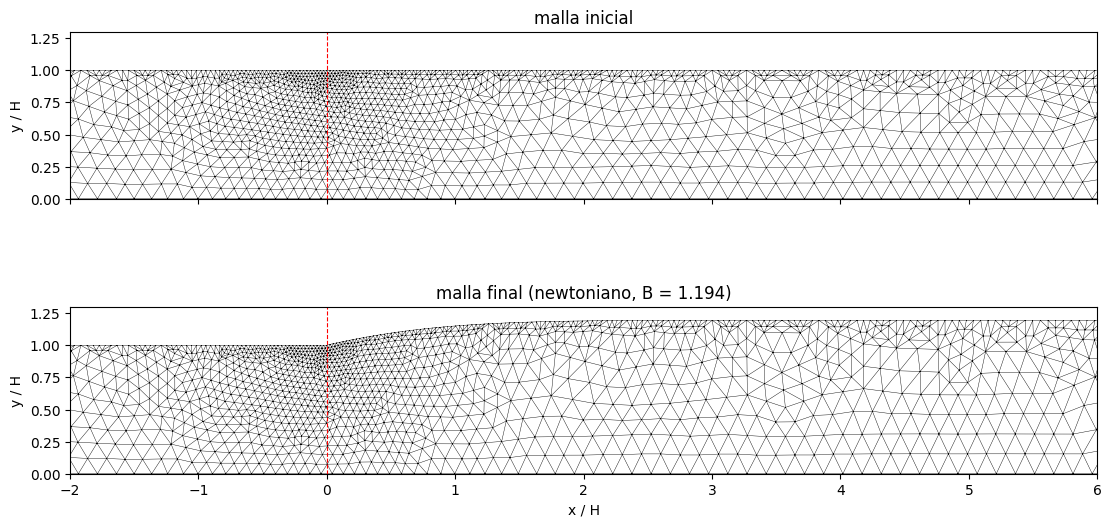

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, constrained_layout=True)
for ax, coords, title in ((axes[0], xy0, 'malla inicial'), (axes[1], xy_n, f'malla final (newtoniano, B = {B_newtonian:.3f})')):
    for node in mesh.NL:
        node.coor = tuple(coords[node.id])
    ax.triplot(mesh.triangulation(), lw=0.3, color='k')
    ax.axvline(0.0, color='r', lw=0.8, ls='--')
    ax.set_xlim(-2, 6); ax.set_ylim(0, 1.3); ax.set_aspect('equal'); ax.set_title(title); ax.set_ylabel('y / H')
axes[1].set_xlabel('x / H')
for node in mesh.NL:
    node.coor = tuple(xy_n[node.id])
plt.show()

### La causa newtoniana: el perfil se vuelve plano

Perfil de $u$ en varias secciones. En el dado es parabólico ($u_{max} = 1.5\,U$); a la salida se aplana. Como el caudal se conserva y la velocidad media baja, la sección crece de $H$ a $B H$.

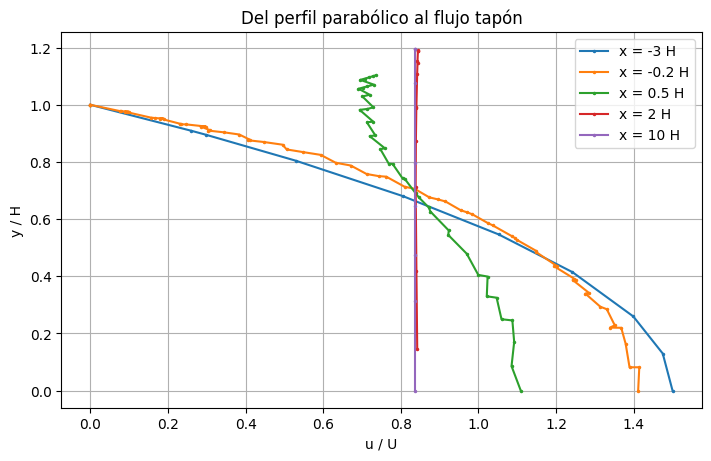

In [5]:
def profile(xy, u, x0, width=0.06):
    near = np.abs(xy[:, 0] - x0) < width
    order = np.argsort(xy[near, 1])
    return xy[near, 1][order], u[near, 0][order]

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
for x0 in (-3.0, -0.2, 0.5, 2.0, 10.0):
    y, ux = profile(xy_n, u_n, x0)
    ax.plot(ux, y, '.-', ms=3, label=f'x = {x0:g} H')
ax.set_xlabel('u / U'); ax.set_ylabel('y / H'); ax.grid(True); ax.legend(); ax.set_title('Del perfil parabólico al flujo tapón')
plt.show()

### Convergencia de la iteración

El cambio máximo de la superficie en cada iteración baja geométricamente, a un factor de ~0.3 por iteración: una docena de iteraciones bastan para $10^{-6} H$.

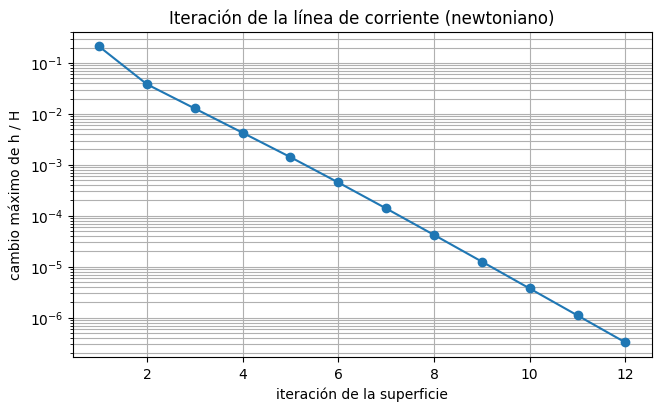

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
ax.semilogy(np.arange(1, len(history_n) + 1), history_n[:, 0], 'o-')
ax.set_xlabel('iteración de la superficie'); ax.set_ylabel('cambio máximo de h / H'); ax.grid(True, which='both')
ax.set_title('Iteración de la línea de corriente (newtoniano)')
plt.show()

## 2. Fluido viscoelástico: Giesekus

Un modo Giesekus con $\alpha = 0.2$ y un solvente $\beta = \mu_s / \mu = 1/9$ (el 89 % de la viscosidad es polimérica). En la entrada, el esfuerzo polimérico es el del flujo desarrollado (`addBC_InflowEdges`), y la salida descuenta la tracción polimérica (`polymer.addBC_OutletEdges`).

**Continuación en Wi**: cada valor de Wi parte de la superficie y los campos del anterior. Se guardan la superficie y los esfuerzos de cada uno.

In [7]:
mesh_ve = extrusion_mesh()
wi = 0.01
model = Model(name='giesekus', dim=2, mesh=mesh_ve, mat=material('X', miu=BETA, rho=1.0), psc=[ff, ve])
flow, polymer = model.physics.fluid, model.physics.viscoelastic
conditions(mesh_ve, flow)
polymer.setModes([(1 - BETA, wi * H / U, ALPHA)])           # (mu_p, lambda, alpha)
polymer.setDEVSS(1 - BETA)
polymer.addBC_OutletEdges(mesh_ve.boundary_edges('outlet'))
polymer.addBC_InflowEdges(mesh_ve.boundary_edges('inlet'), lambda x, y: [[0.0, -3.0 * U * y / H ** 2], [0.0, 0.0]])
model.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear)
print(f"{model.layout.ndof} incognitas (u, p, raiz de la conformacion b y gradiente proyectado G)")

surface = FreeSurface(model, mesh_ve.boundary_edges('surface'), lip=0.0)
results = {}
for target in (0.01, 0.25, 0.5, 1.0, 1.5, 2.0):
    polymer.setWeissenberg(target / wi)
    wi = target
    start = time.perf_counter()
    print(f"\nWi = {wi:.2f}")
    if not surface.solve(tol=1e-6):
        print(f"Wi = {wi:.2f}: la superficie no converge; se detiene la continuacion")
        break
    results[wi] = {'B': surface.swell(), 'surface': surface.height(), 'xy': np.array([n.coor for n in mesh_ve.NL]),
                   'u': np.array(model.sol['u']), 'tau': np.array(model.sol['polymer_stress'])}
    print(f"Wi = {wi:.2f}: B = {surface.swell():.4f} ({time.perf_counter() - start:.0f} s)")
    surface.history = []

30240 incognitas (u, p, raiz de la conformacion b y gradiente proyectado G)

Wi = 0.01
   superficie libre   1: cambio de h 2.04e-01 H, hinchamiento 1.20376, |u.n|/|u| max 3.6e-01, 3 it. del flujo, 6.9 s (total 7 s)
   superficie libre   2: cambio de h 3.47e-02 H, hinchamiento 1.18504, |u.n|/|u| max 1.3e-01, 3 it. del flujo, 5.2 s (total 12 s)
   superficie libre   3: cambio de h 1.12e-02 H, hinchamiento 1.19118, |u.n|/|u| max 6.2e-02, 3 it. del flujo, 5.3 s (total 17 s)
   superficie libre   4: cambio de h 3.67e-03 H, hinchamiento 1.18919, |u.n|/|u| max 4.1e-02, 2 it. del flujo, 3.8 s (total 21 s)
   superficie libre   5: cambio de h 1.22e-03 H, hinchamiento 1.18986, |u.n|/|u| max 2.9e-02, 2 it. del flujo, 3.6 s (total 25 s)
   superficie libre   6: cambio de h 3.92e-04 H, hinchamiento 1.18964, |u.n|/|u| max 3.1e-02, 2 it. del flujo, 3.7 s (total 28 s)
   superficie libre   7: cambio de h 1.25e-04 H, hinchamiento 1.18971, |u.n|/|u| max 3.0e-02, 2 it. del flujo, 3.9 s (total 32 s)
   s

### El efecto de la elasticidad en el hinchamiento

A Wi muy bajo el hinchamiento coincide con el newtoniano, y el efecto elástico es lineal en Wi (`Test/manual/die_swell_ve.py`: $dB/d\mathrm{Wi} \approx -0.45$). Para Giesekus con $\beta = 1/9$, **una elasticidad pequeña reduce el hinchamiento**: hay un mínimo cerca de Wi ≈ 0.25. Después **lo aumenta casi linealmente**: la relajación de $N_1$ fuera del dado domina. Las dos tendencias son las publicadas para flujo plano. No se encontró una tabla de referencia abierta para comparar los valores.

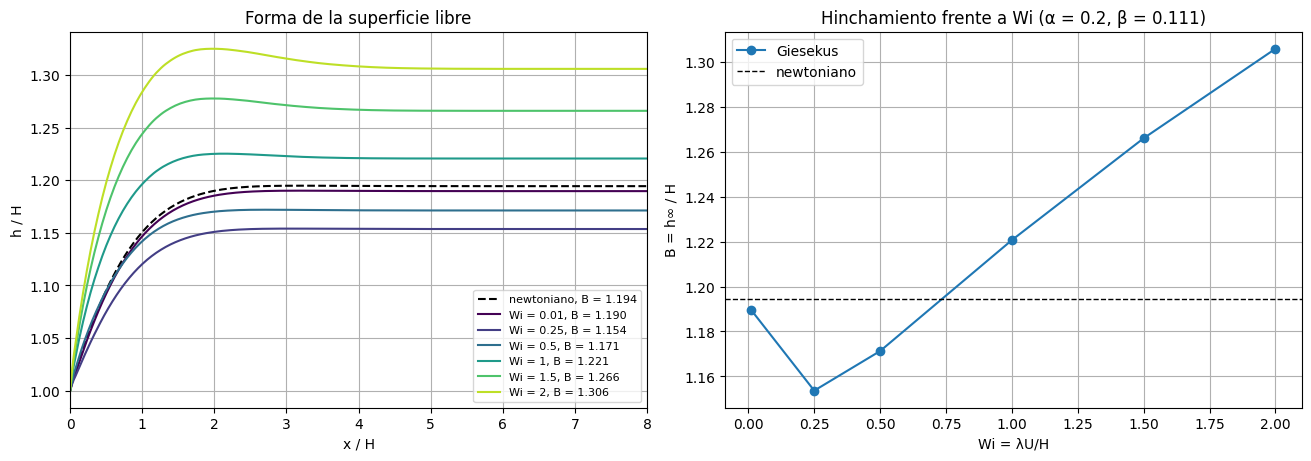

In [8]:
wis = np.array(sorted(results))
Bs = np.array([results[w]['B'] for w in wis])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
s, h = surface_n.height()
axes[0].plot(s, h, 'k--', lw=1.5, label=f'newtoniano, B = {B_newtonian:.3f}')
for w, c in zip(wis, plt.cm.viridis(np.linspace(0, 0.9, len(wis)))):
    s, h = results[w]['surface']
    axes[0].plot(s, h, color=c, label=f'Wi = {w:g}, B = {results[w]["B"]:.3f}')
axes[0].set_xlim(0, 8); axes[0].set_xlabel('x / H'); axes[0].set_ylabel('h / H'); axes[0].grid(True); axes[0].legend(fontsize=8)
axes[0].set_title('Forma de la superficie libre')

axes[1].plot(wis, Bs, 'o-', label='Giesekus')
axes[1].axhline(B_newtonian, color='k', ls='--', lw=1, label='newtoniano')
axes[1].set_xlabel('Wi = λU/H'); axes[1].set_ylabel('B = h∞ / H'); axes[1].grid(True); axes[1].legend()
axes[1].set_title(f'Hinchamiento frente a Wi (α = {ALPHA}, β = {BETA:.3f})')
plt.show()

### Los esfuerzos normales que se relajan

$N_1 = \tau_{xx} - \tau_{yy}$ del polímero sobre el dominio deformado, para el Wi más alto resuelto. Junto a la pared del dado $N_1$ es grande, el fluido sale "estirado", y fuera del dado se relaja en una distancia del orden de $\lambda U$. El máximo está en el borde del dado, donde el esfuerzo es singular.

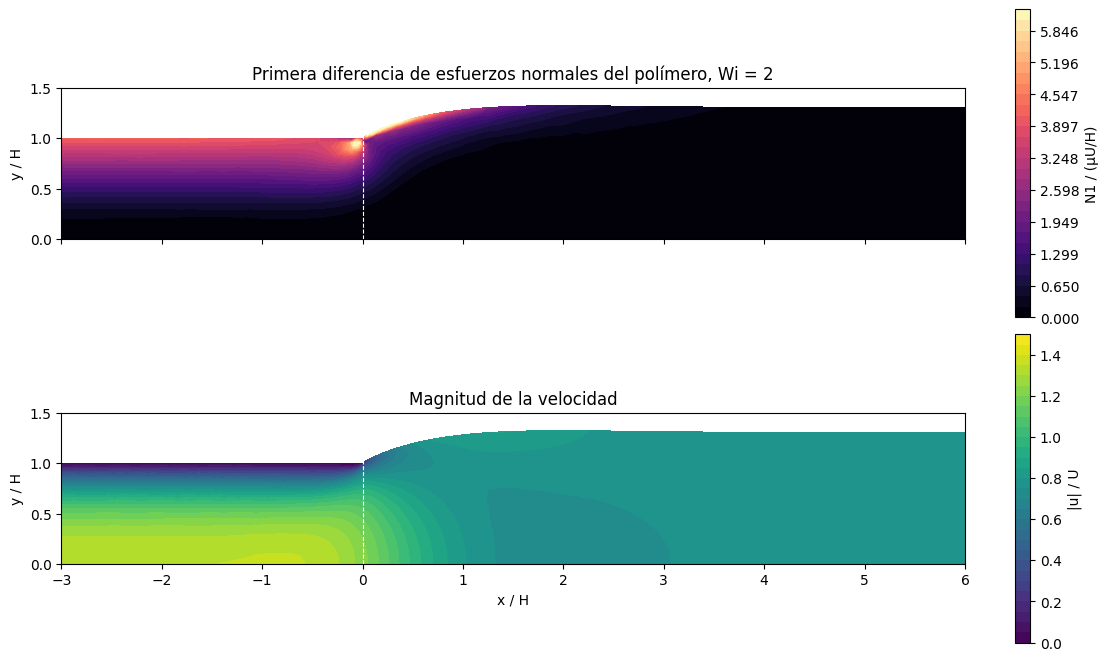

In [9]:
w_last = wis[-1]
for node in mesh_ve.NL:
    node.coor = tuple(results[w_last]['xy'][node.id])
tau = results[w_last]['tau']
N1 = tau[:, 0] - tau[:, 2]
speed = np.linalg.norm(results[w_last]['u'], axis=1)
tri = mesh_ve.triangulation()

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, constrained_layout=True)
levels = np.linspace(0, np.percentile(N1, 99.5), 30)
c = axes[0].tricontourf(tri, np.clip(N1, 0, levels[-1]), levels=levels, cmap='magma')
fig.colorbar(c, ax=axes[0], label='N1 / (μU/H)')
axes[0].set_title(f'Primera diferencia de esfuerzos normales del polímero, Wi = {w_last:g}')
c = axes[1].tricontourf(tri, speed, levels=30, cmap='viridis')
fig.colorbar(c, ax=axes[1], label='|u| / U')
axes[1].set_title('Magnitud de la velocidad')
for ax in axes:
    ax.set_xlim(-3, 6); ax.set_ylim(0, 1.5); ax.set_aspect('equal'); ax.axvline(0, color='w', lw=0.8, ls='--'); ax.set_ylabel('y / H')
axes[1].set_xlabel('x / H')
plt.show()

$N_1$ a lo largo de la línea $y = 0.9\,h(x)$, cerca de la superficie, para cada Wi: la relajación fuera del dado es más lenta, y llega más lejos, cuanto mayor es Wi.

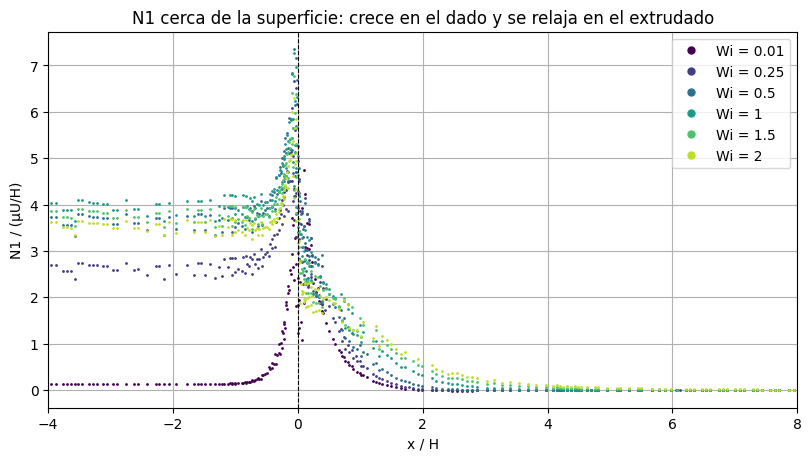

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for w, c in zip(wis, plt.cm.viridis(np.linspace(0, 0.9, len(wis)))):
    xy, tau = results[w]['xy'], results[w]['tau']
    s, h = results[w]['surface']
    level = 0.9 * np.interp(xy[:, 0], s, h, left=H)
    band = np.abs(xy[:, 1] - level) < 0.04
    order = np.argsort(xy[band, 0])
    N1 = (tau[band, 0] - tau[band, 2])[order]
    ax.plot(xy[band, 0][order], N1, '.', ms=2, color=c, label=f'Wi = {w:g}')
ax.axvline(0, color='k', ls='--', lw=0.8)
ax.set_xlim(-4, 8); ax.set_xlabel('x / H'); ax.set_ylabel('N1 / (μU/H)'); ax.grid(True); ax.legend(markerscale=5)
ax.set_title('N1 cerca de la superficie: crece en el dado y se relaja en el extrudado')
plt.show()

## Notas y límites

- **Malla**: el borde del dado es una singularidad, y el hinchamiento converge lentamente con la malla (orden ≈ 0.8 en newtoniano). Para valores finales use `LIP = 0.0125` o menos; aquí la malla gruesa difiere en ~0.3 %.
- **Wi alto**: con este método segregado la iteración convergió hasta Wi = 3 en `Test/manual/die_swell_ve.py`. Más allá puede no converger: es el límite conocido del método, y el problema del Weissenberg alto en el borde.
- **Fuera de alcance**: tensión superficial, gravedad, enfriamiento del extrudado (el viscoelástico no isotermo existe, pero no se ha probado con superficie libre) y 3D.
- El mismo módulo sirve en **axisimétrico** (dado circular): `FreeSurface(model, edges, lip=0.0, along=1)` con la malla en (r, z).